# Phase and Amplitude Coupling in APMSD

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hy20577/complex-network-dynamics/blob/main/mkdoc_material/docs/tutorials/07_phase_and_amplitude_coupling.ipynb)

In the [previous tutorial](06_apmsd_network_inference.ipynb) we inferred a network with the
mutual information rate (MIR) and amplitude-phase modulated surrogate data (APMSD), following
Yıldırım & Antonopoulos [[1](#ref-1)]. The method
replaces a fraction $p_{c1}$ of the instantaneous **amplitudes** and a fraction $p_{c2}$ of the
instantaneous **phases** of every signal by random values, and calls a pair of nodes connected
when the MIR of the data is higher than the MIR of its surrogates. The pairs $(p_{c1}, p_{c2})$
that give perfect inference change from one system to another: in the paper they lie at
$p_{c2} = 100\%$ for the stochastic Kuramoto oscillators (Section 3.4.3) but at small $p_{c2}$
for the logistic maps.

Why? In this tutorial we test a simple explanation: **the good cells depend on the channel through
which the nodes interact**. A pair of nodes can share its phase (the oscillations happen at the
same time), its amplitude (the oscillations grow and shrink together), or both. To check this we
build a toy model in which every link can be switched on in the phase only or in the amplitude
only, something no real system allows.

You will learn:

1. how to simulate oscillators whose phase and amplitude are coupled separately;
2. how to measure phase and amplitude relations between pairs with the Hilbert transform;
3. what the APMSD surrogates do to a signal;
4. where in the $(p_{c1}, p_{c2})$ plane a phase link and an amplitude link are detected;
5. what happens in a network that mixes both kinds of link, and why indirect pairs are a problem.

Running the whole notebook takes about 2–3 minutes on a laptop.

In [1]:
try:
    import complex_network_dynamics as cnd
except ImportError:  # e.g. on Google Colab: install the library from GitHub
    %pip install -q git+https://github.com/hy20577/complex-network-dynamics.git
    import complex_network_dynamics as cnd

import time
from itertools import combinations

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.ndimage import uniform_filter1d
from scipy.signal import hilbert

## 1. The model: oscillators with separate phase and amplitude

Each node $i$ is a noisy oscillator,

$$
x_i(t) = a_i(t) \cos\theta_i(t),
$$

whose **phase** $\theta_i(t)$ and **amplitude** $a_i(t) > 0$ are two separate random processes.
The phase follows a noisy Kuramoto equation (Eq. (11) of the paper, with noise), and the
logarithm of the amplitude, $\ell_i = \log a_i$, an Ornstein–Uhlenbeck (OU) process:

$$
d\theta_i = \Big(\omega_i + K \sum_j C^{\theta}_{ij} \sin(\theta_j - \theta_i)\Big)\,dt + \sigma_\theta\, dW_i,
$$

$$
d\ell_i = \Big(-\frac{\ell_i}{\tau} + k \sum_j C^{a}_{ij} \big(\ell_j - \ell_i\big)\Big)\,dt + \sigma_a \sqrt{2/\tau}\; dV_i .
$$

- $\omega_i$ is the natural frequency of node $i$, and $\sigma_\theta$ the strength of its phase noise.
- $C^{\theta}_{ij} = 1$ means node $i$ is pulled towards the **phase** of node $j$, with strength $K$.
- $\tau$ is how long the amplitude remembers its past, and $\sigma_a$ how much $\ell_i$ fluctuates
  when the node is not coupled.
- $C^{a}_{ij} = 1$ means node $i$ is pulled towards the **amplitude** of node $j$, with strength $k$.
- $W_i$ and $V_i$ are independent Wiener processes (white noise).

Because the phase and the amplitude of every node are driven by independent noises and coupled
through separate matrices, a link in $C^{\theta}$ creates a relation between two phases and none
between the amplitudes, and a link in $C^{a}$ the opposite. We use the logarithm of the amplitude
so that $a_i = e^{\ell_i}$ stays positive.

We integrate the equations with the **Euler–Maruyama** method, the stochastic version of Euler's
method: at every step $\Delta t$ each deterministic term is multiplied by $\Delta t$ and each noise
term by $\sqrt{\Delta t}$ times a standard normal random number,

$$
\theta_i \leftarrow \theta_i + \Big(\omega_i + K \sum_j C^{\theta}_{ij} \sin(\theta_j - \theta_i)\Big)\Delta t + \sigma_\theta \sqrt{\Delta t}\,\xi_i,
\qquad
\ell_i \leftarrow \ell_i + \Big(-\frac{\ell_i}{\tau} + k \sum_j C^{a}_{ij}(\ell_j - \ell_i)\Big)\Delta t + \sigma_a\sqrt{\frac{2\Delta t}{\tau}}\,\eta_i .
$$

We use $\Delta t = 0.01$, drop the first $5 \times 10^4$ steps as a transient, and then keep one
point every 25 steps (every 0.25 time units, about 25 points per oscillation) until we have
$L = 2 \times 10^4$ points.

In [2]:
def simulate_oscillators(w, C_phase, C_amp, n_points=20_000, dt=0.01, sample_every=25,
                         n_transient=50_000, K=0.5, k=0.5, sigma_phase=0.1, tau=10.0,
                         sigma_amp=0.5, rng=None):
    # Signals x_i = a_i cos(theta_i) with separate phase (C_phase) and amplitude (C_amp) coupling.
    # C[i, j] = 1 means node i is driven by node j. Returns x, a and theta, each (n_points, n_nodes).
    rng = np.random.default_rng(rng)
    w = np.asarray(w, dtype=float)
    n = len(w)
    theta = rng.uniform(0, 2 * np.pi, n)   # random initial phases
    loga = np.zeros(n)                     # initial amplitudes a_i = 1
    x_theta = np.empty((n_points, n))
    x_loga = np.empty((n_points, n))
    noise_phase = sigma_phase * np.sqrt(dt)
    noise_amp = sigma_amp * np.sqrt(2 * dt / tau)
    kept = 0
    for step in range(n_transient + n_points * sample_every):
        # deterministic parts of the two equations
        dtheta = w + K * (C_phase * np.sin(theta[None, :] - theta[:, None])).sum(axis=1)
        dloga = -loga / tau + k * (C_amp * (loga[None, :] - loga[:, None])).sum(axis=1)
        # Euler-Maruyama step
        theta = theta + dtheta * dt + noise_phase * rng.standard_normal(n)
        loga = loga + dloga * dt + noise_amp * rng.standard_normal(n)
        if step >= n_transient and (step - n_transient) % sample_every == 0:
            x_theta[kept], x_loga[kept] = theta, loga
            kept += 1
    a = np.exp(x_loga)
    return a * np.cos(x_theta), a, x_theta

## 2. A driver, a phase follower and an amplitude follower

We start with four nodes:

| node | frequency $\omega$ | phase | amplitude |
|---|---|---|---|
| **D**, driver | 1.00 | free | free |
| **P**, phase follower | 1.10 | pulled towards D's phase | free |
| **M**, amplitude follower | 0.90 | free | pulled towards D's amplitude |
| **C**, control | 1.05 | free | free |

So the true links are **D–P (phase only)** and **D–M (amplitude only)**. P and M are not linked:
P copies D's phase and M copies D's amplitude, so they have nothing in common. The coupling here
is one-way (D drives, P and M follow), which is why only one entry of each matrix is set.

In [3]:
names = ["D", "P", "M", "C"]
C_phase = np.zeros((4, 4))
C_amp = np.zeros((4, 4))
C_phase[1, 0] = 1  # P follows D's phase
C_amp[2, 0] = 1    # M follows D's amplitude

start = time.time()
data, a, theta = simulate_oscillators([1.0, 1.1, 0.9, 1.05], C_phase, C_amp, rng=0)
print(f"data shape {data.shape}, simulated in {time.time() - start:.1f} s")

# the true network: a link in either channel, in either direction
A = ((C_phase + C_amp + C_phase.T + C_amp.T) > 0).astype(float)

data shape (20000, 4), simulated in 6.3 s


Let us look at what we simulated. Panel (a) shows the signals: they all look like noisy
oscillations, and by eye one cannot tell who is coupled to whom. Panel (b) shows the phase
difference between the driver and each other node: P stays locked to D (its difference stays near
zero), while M and C drift through all values. Panel (c) shows the amplitudes: M rises and falls
with D, P does not.

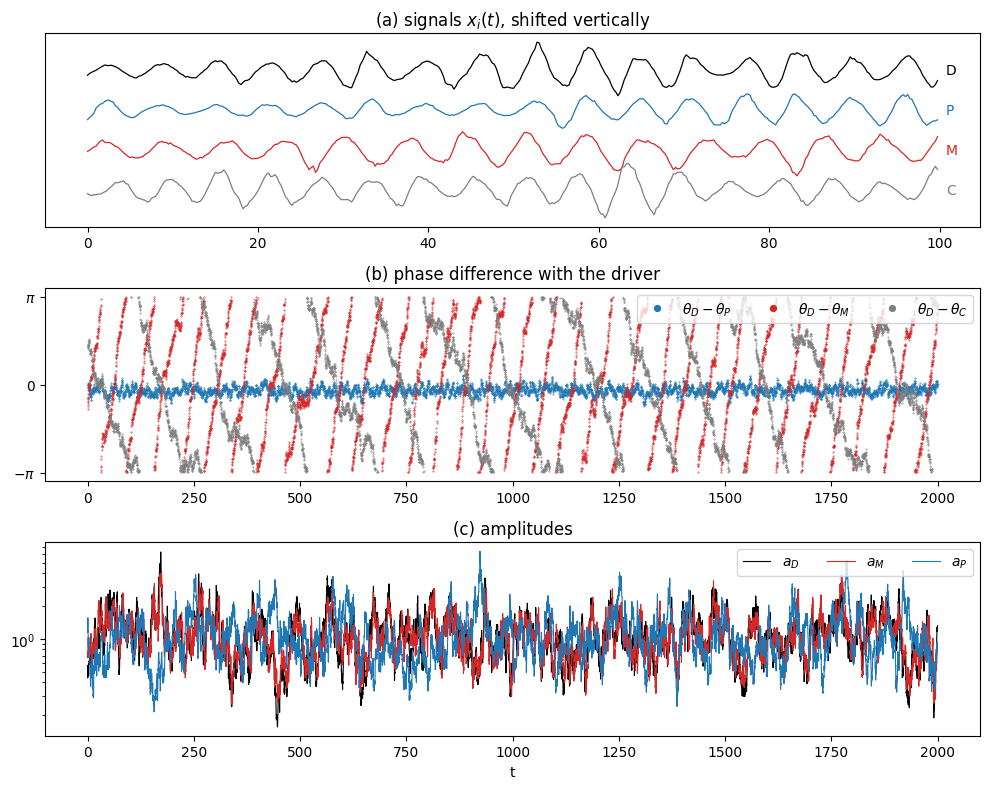

In [4]:
t = 0.25 * np.arange(len(data))
colours = {"D": "black", "P": "tab:blue", "M": "tab:red", "C": "tab:grey"}
fig, axes = plt.subplots(3, 1, figsize=(10, 8))

w = slice(0, 400)
for k, name in enumerate(names):
    axes[0].plot(t[w], data[w, k] + 4 * (3 - k), color=colours[name], lw=0.9)
    axes[0].text(t[w][-1] + 1, 4 * (3 - k), name, color=colours[name], va="center")
axes[0].set_yticks([])
axes[0].set_title("(a) signals $x_i(t)$, shifted vertically")

w = slice(0, 8000)
for k in [1, 2, 3]:
    diff = np.angle(np.exp(1j * (theta[w, 0] - theta[w, k])))  # wrapped to [-pi, pi]
    axes[1].plot(t[w], diff, ".", ms=0.7, color=colours[names[k]], label=f"$\\theta_D - \\theta_{names[k]}$")
axes[1].set_yticks([-np.pi, 0, np.pi], [r"$-\pi$", "0", r"$\pi$"])
axes[1].legend(loc="upper right", markerscale=12, ncol=3)
axes[1].set_title("(b) phase difference with the driver")

for k in [0, 2, 1]:
    axes[2].plot(t[w], a[w, k], color=colours[names[k]], lw=0.8, label=f"$a_{names[k]}$")
axes[2].set_yscale("log")
axes[2].legend(loc="upper right", ncol=3)
axes[2].set_title("(c) amplitudes")
axes[2].set_xlabel("t")
plt.tight_layout()
plt.show()

## 3. Measuring phase and amplitude relations from the data

In practice we only see the signals $x_i(t)$, not $\theta_i$ and $a_i$. APMSD recovers an
amplitude and a phase from each signal with the **Hilbert transform** $\mathcal{H}$, which builds
the analytic signal

$$
z_i(t) = x_i(t) + i\,\mathcal{H}[x_i](t) = A_i(t)\, e^{i \phi_i(t)} ,
$$

with instantaneous amplitude $A_i = |z_i|$ and phase $\phi_i = \arg z_i$. For a narrow-band
oscillation like ours, $A_i \approx a_i$ and $\phi_i \approx \theta_i$.

From these we measure two relations for every pair:

- the **phase-locking value**, $\mathrm{PLV}_{ij} = \left|\langle e^{i(\phi_i - \phi_j)}\rangle_t\right|$
  (the pairwise phase synchronisation of Eq. (16) in the paper): 1 for locked phases, near 0
  for independent ones;
- the **amplitude correlation**: Pearson's correlation between $A_i(t)$ and $A_j(t)$.

> **Remove the mean first.** The Hilbert transform of a constant is zero, so a signal with a
> large mean $\mu$ gives $z(t) = \mu + (\text{small oscillation})$: its phase hovers around 0 for
> every node, and every pair looks phase-locked even when the nodes are not coupled at all.
> Our signals have mean close to zero, but for data such as the logistic map (values in $[0, 1]$)
> subtracting each node's mean before the transform is essential.

In [5]:
def channel_relations(data):
    # PLV and amplitude correlation of every pair, from the Hilbert transform of the demeaned signals
    z = hilbert(data - data.mean(axis=0), axis=0)
    plv = cnd.pairwise_sync(np.angle(z))
    amp = np.corrcoef(np.abs(z).T)
    return plv, amp


def relations_table(data, A, labels):
    plv, amp = channel_relations(data)
    rows = []
    for i, j in combinations(range(len(A)), 2):
        rows.append({"pair": f"{labels[i]}-{labels[j]}", "linked": bool(A[i, j]),
                     "PLV": round(plv[i, j], 3), "amplitude corr.": round(amp[i, j], 3)})
    return pd.DataFrame(rows)


relations_table(data, A, names)

,pair,linked,PLV,amplitude corr.
0,D-P,True,0.982,0.025
1,D-M,True,0.021,0.790
2,D-C,False,0.012,-0.002
3,P-M,False,0.026,0.047
4,P-C,False,0.012,-0.040
5,M-C,False,0.008,-0.020


The measures find exactly what we built in: D–P has PLV close to 1 and no amplitude correlation,
D–M has a strong amplitude correlation and PLV close to 0, and every other pair is near zero in
both.

## 4. What the APMSD surrogates do to a signal

To build a surrogate, `cnd.amplitude_phase_surrogates` takes the Hilbert amplitude and phase of
every node, replaces a random fraction $p_{c1}$ of the amplitudes by random values between the
smallest and largest amplitude, and a random fraction $p_{c2}$ of the phases by random values
between the smallest and largest phase, and returns the real part, $A\cos\phi$. The plot shows the
driver's signal (black) and one surrogate (orange) in four cells:

- at $(0, 0)\%$ nothing is changed, so the surrogate equals the data;
- at $(100, 0)\%$ the phases are kept, so the surrogate still oscillates **in step** with the data,
  but its size is random at every point: the amplitude relation with other nodes is destroyed;
- at $(0, 100)\%$ the amplitudes are kept but the phase is random at every point, so the
  oscillation, and with it any phase relation, is lost.

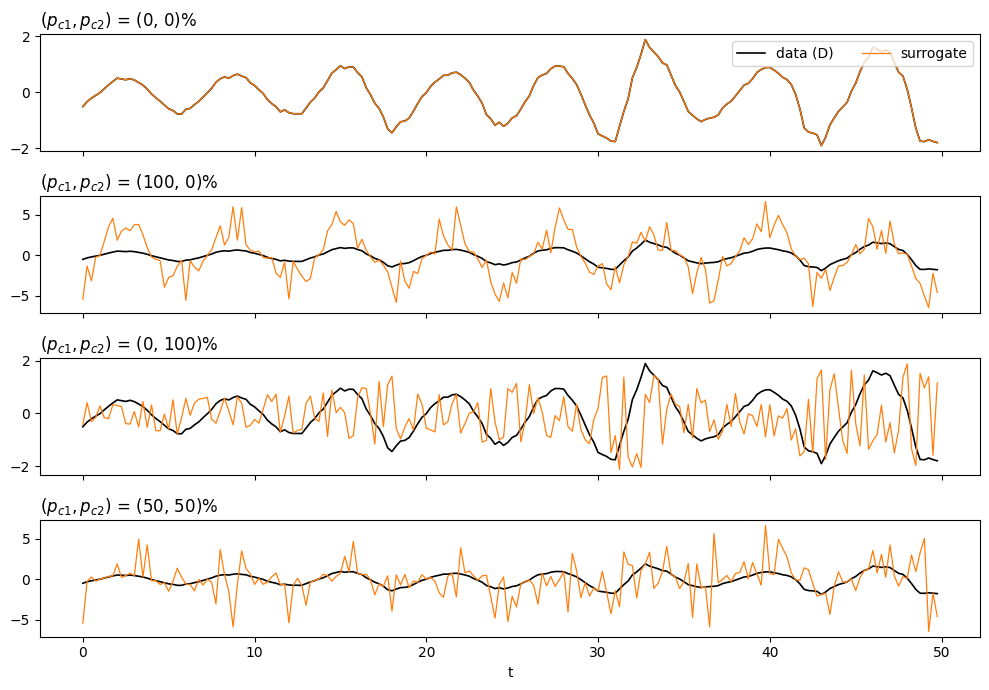

In [6]:
cells_to_show = [(0, 0), (1, 0), (0, 1), (0.5, 0.5)]
fig, axes = plt.subplots(len(cells_to_show), 1, figsize=(10, 7), sharex=True)
w = slice(0, 200)
for ax, (pc1, pc2) in zip(axes, cells_to_show):
    surrogate = cnd.amplitude_phase_surrogates(data, 1, pc_amplitude=pc1, pc_phase=pc2, rng=1)[0]
    ax.plot(t[w], data[w, 0], color="black", lw=1.2, label="data (D)")
    ax.plot(t[w], surrogate[w, 0], color="tab:orange", lw=0.9, label="surrogate")
    ax.set_title(f"$(p_{{c1}}, p_{{c2}})$ = ({pc1 * 100:.0f}, {pc2 * 100:.0f})%", loc="left")
axes[0].legend(loc="upper right", ncol=2)
axes[-1].set_xlabel("t")
plt.tight_layout()
plt.show()

## 5. Where is each link detected?

Now we run the full method of the paper over the $11 \times 11$ grid of $(p_{c1}, p_{c2})$, with
10 surrogates per cell ($p_{sl} = 0.1$), using `cnd.mir_surrogate_test`. For every cell we keep
the inferred network, so we can see in which cells **each pair** is called a link, as well as the
TPR and FPR.

In [7]:
LEVELS = np.linspace(0, 1, 11)


def apmsd_grid(data, true_network, levels=LEVELS, rng=0):
    # Run the APMSD hypothesis test in every cell of the (p_c1, p_c2) grid.
    # Returns found[i, j, pair] (True where the pair is inferred as a link), TPR and FPR.
    rng = np.random.default_rng(rng)
    pairs = list(combinations(range(len(true_network)), 2))
    found = np.zeros((len(levels), len(levels), len(pairs)), dtype=bool)
    tpr = np.zeros((len(levels), len(levels)))
    fpr = np.zeros((len(levels), len(levels)))
    for i, pc1 in enumerate(levels):
        for j, pc2 in enumerate(levels):
            _, adjacency, rates = cnd.mir_surrogate_test(data, p_sl=0.1, true_network=true_network,
                                                         pc_amplitude=pc1, pc_phase=pc2, rng=rng)
            found[i, j] = [adjacency[0][p] > 0 for p in pairs]
            tpr[i, j], fpr[i, j] = rates[0, 1:]
    return found, tpr, fpr


start = time.time()
found, tpr, fpr = apmsd_grid(data, A)
print(f"121 cells in {time.time() - start:.0f} s")

121 cells in 27 s


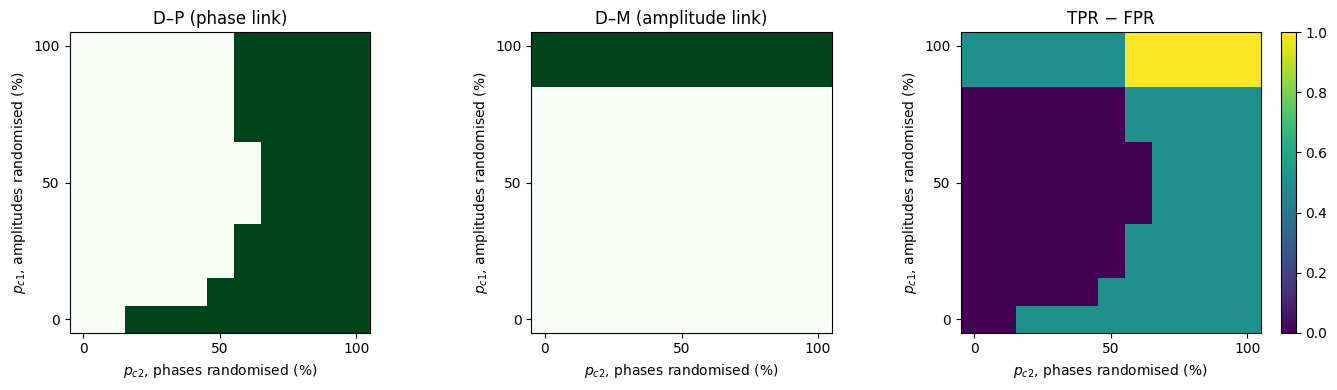

D-P: inferred as a link in  57 of 121 cells
D-M: inferred as a link in  22 of 121 cells
D-C: inferred as a link in   0 of 121 cells
P-M: inferred as a link in   0 of 121 cells
P-C: inferred as a link in   0 of 121 cells
M-C: inferred as a link in   0 of 121 cells
perfect cells (TPR = 1, FPR = 0): 10


In [8]:
def show_plane(ax, z, title, cmap="Greens", vmin=0, vmax=1, levels=LEVELS):
    im = ax.imshow(z, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax,
                   extent=[-5, 105, -5, 105])
    ax.set_xticks([0, 50, 100])
    ax.set_yticks([0, 50, 100])
    ax.set_xlabel("$p_{c2}$, phases randomised (%)")
    ax.set_ylabel("$p_{c1}$, amplitudes randomised (%)")
    ax.set_title(title)
    return im

pairs = list(combinations(range(4), 2))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
show_plane(axes[0], found[:, :, pairs.index((0, 1))], "D–P (phase link)")
show_plane(axes[1], found[:, :, pairs.index((0, 2))], "D–M (amplitude link)")
im = show_plane(axes[2], tpr - fpr, "TPR − FPR", cmap="viridis")
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()

for (i, j), k in zip(pairs, range(len(pairs))):
    print(f"{names[i]}-{names[j]}: inferred as a link in {found[:, :, k].sum():3d} of 121 cells")
print("perfect cells (TPR = 1, FPR = 0):", int(((tpr == 1) & (fpr == 0)).sum()))

This is the main result of the tutorial:

- the **phase link** D–P is detected in a **vertical band**: once enough phases are randomised
  ($p_{c2}$ large), whatever happens to the amplitudes;
- the **amplitude link** D–M is detected in a **horizontal band**: only when almost all amplitudes
  are randomised ($p_{c1} \ge 90\%$), whatever happens to the phases;
- the unlinked pairs are never (or almost never) detected;
- **perfect inference** happens only where the two bands overlap, the top-right corner.

So the position of the good cells tells us *how* the nodes are coupled. A surrogate can only reveal
a link if it destroys the channel that carries it.

Note that the two axes are not on the same scale: the amplitude link needs almost all amplitudes
randomised, the phase link a much smaller share of the phases. The amplitude changes slowly
($\tau = 10$ time units, about 40 points), so the amplitudes left untouched between randomised
points still carry most of the correlation, whereas a single random phase changes the sign of the
signal.

## 6. A network with phase links and amplitude links

Can one network have some links through the phase and others through the amplitude? In our model,
yes: we only need to put them in different matrices. We build eight nodes with **mutual** coupling
($C_{ij} = C_{ji}$):

- phase links: 1–2, 2–3, 5–6;
- amplitude links: 3–4, 4–5, 6–7;
- a link through both: 7–8.

Node 3 takes part in both kinds of link (phase with 2, amplitude with 4). The chains 1–2–3 (phase),
3–4–5 and 6–7–8 (amplitude) will also create **indirect** relations: 1 and 3 are both locked to 2,
so they are locked to each other, even though they are not linked.

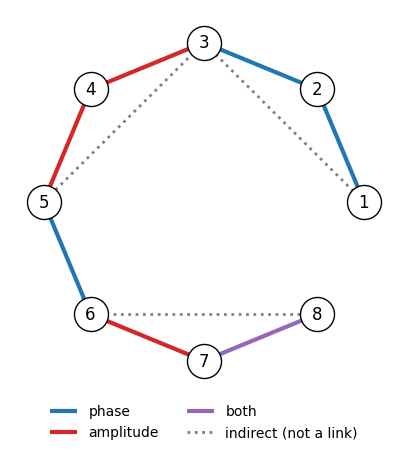

In [9]:
# Nodes are numbered 1 to 8
phase_links = [(1, 2), (2, 3), (5, 6)]
amplitude_links = [(3, 4), (4, 5), (6, 7)]
both_links = [(7, 8)]
indirect_pairs = [(1, 3), (3, 5), (6, 8)]
n_nodes = 8

C_phase_net = np.zeros((n_nodes, n_nodes))
C_amp_net = np.zeros((n_nodes, n_nodes))
for i, j in phase_links + both_links:
    C_phase_net[i - 1, j - 1] = C_phase_net[j - 1, i - 1] = 1  # row i - 1 is node i
for i, j in amplitude_links + both_links:
    C_amp_net[i - 1, j - 1] = C_amp_net[j - 1, i - 1] = 1
A_net = ((C_phase_net + C_amp_net) > 0).astype(float)

G = nx.from_numpy_array(A_net)
G = nx.relabel_nodes(G, {v: v + 1 for v in G})
pos = nx.circular_layout(G)
plt.figure(figsize=(5, 5))
nx.draw_networkx_nodes(G, pos, node_color="white", edgecolors="black", node_size=600)
nx.draw_networkx_labels(G, pos)
nx.draw_networkx_edges(G, pos, edgelist=phase_links, edge_color="tab:blue", width=3, label="phase")
nx.draw_networkx_edges(G, pos, edgelist=amplitude_links, edge_color="tab:red", width=3, label="amplitude")
nx.draw_networkx_edges(G, pos, edgelist=both_links, edge_color="tab:purple", width=3, label="both")
nx.draw_networkx_edges(G, pos, edgelist=indirect_pairs, edge_color="grey", style=":",
                       width=2, label="indirect (not a link)")
plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.axis("off")
plt.show()

In [10]:
w_net = 1 + 0.05 * np.arange(n_nodes)  # frequencies 1.00, 1.05, ..., 1.35
data_net, a_net, theta_net = simulate_oscillators(w_net, C_phase_net, C_amp_net, rng=0)
labels = [str(i + 1) for i in range(n_nodes)]

table = relations_table(data_net, A_net, labels)
table[(table["PLV"] > 0.1) | (table["amplitude corr."] > 0.1)]  # the pairs with a clear relation

,pair,linked,PLV,amplitude corr.
0,1-2,True,0.987,-0.004
1,1-3,False,0.983,0.001
7,2-3,True,0.988,0.017
13,3-4,True,0.012,0.810
14,3-5,False,0.010,0.665
18,4-5,True,0.005,0.809
22,5-6,True,0.990,-0.014
25,6-7,True,0.004,0.811
26,6-8,False,0.002,0.629
27,7-8,True,0.991,0.801


The table lists the pairs with a clear relation. Besides the seven links, three unlinked pairs
appear: **1–3** is phase-locked through node 2 (its PLV is as high as that of a real link), and
**3–5** and **6–8** have correlated amplitudes through nodes 4 and 7. Now the APMSD grid:

121 cells in 78 s


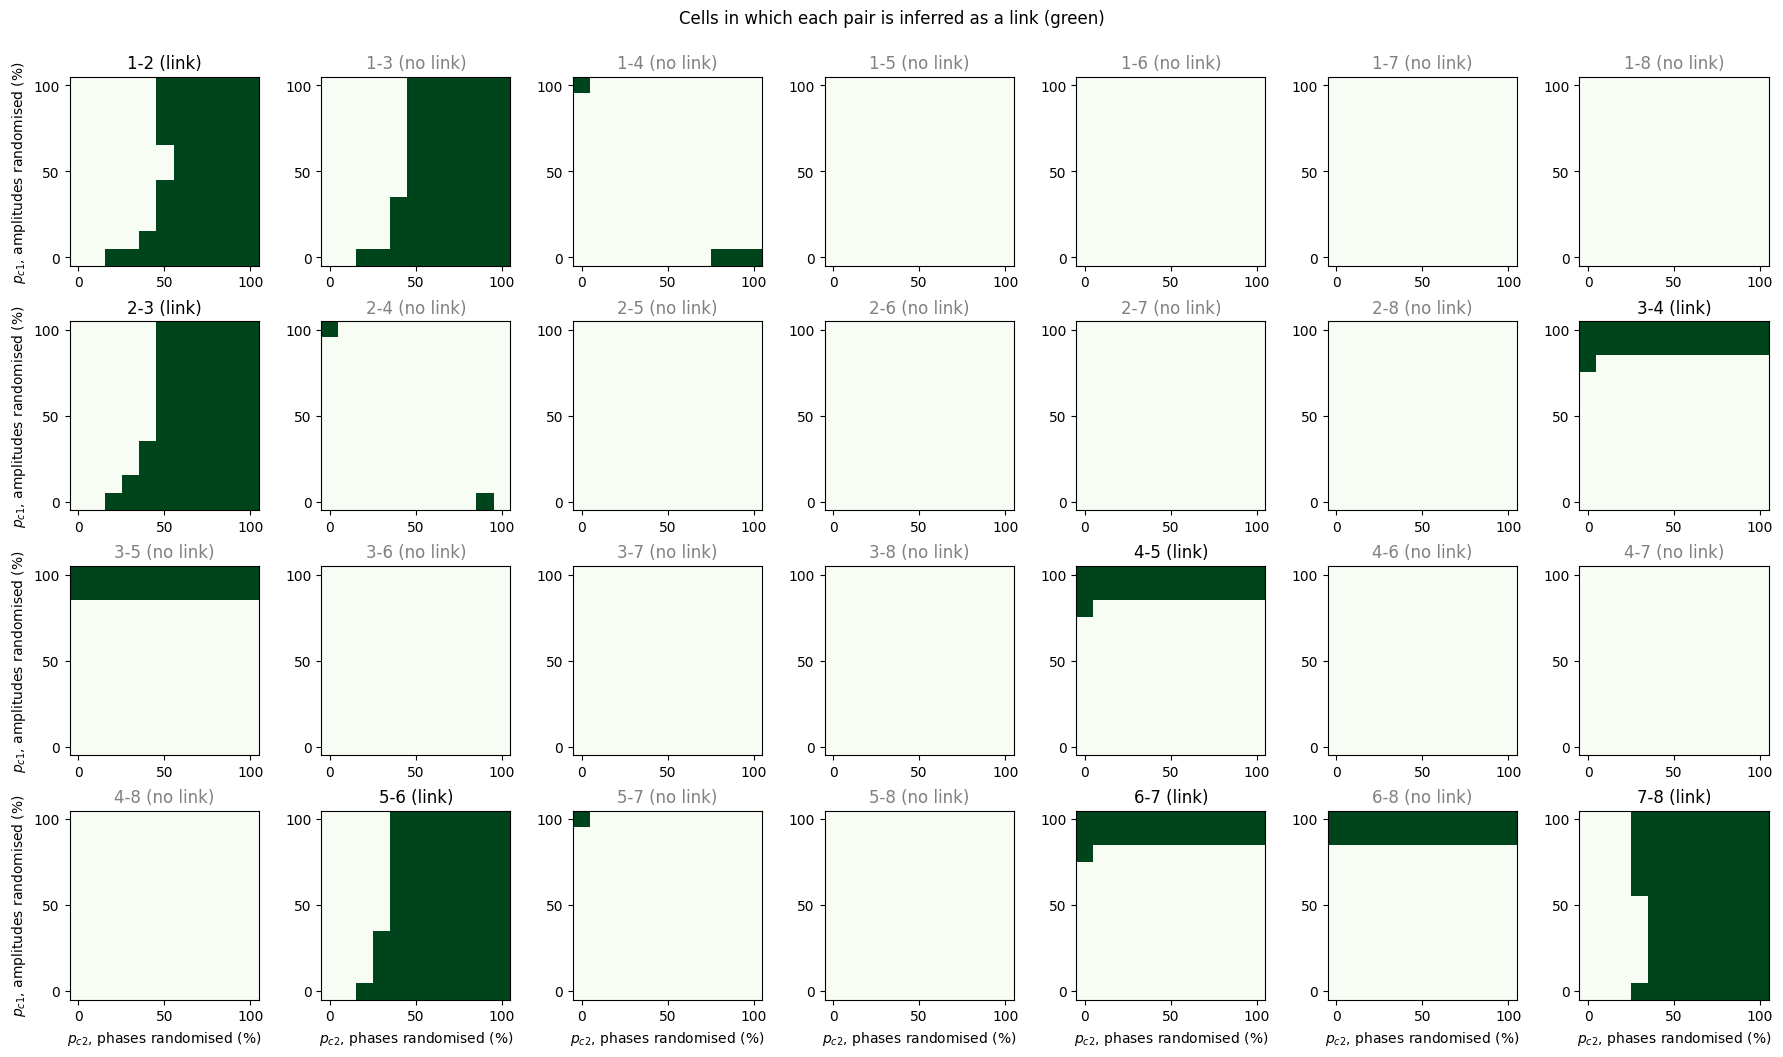

In [11]:
start = time.time()
found_net, tpr_net, fpr_net = apmsd_grid(data_net, A_net)
print(f"121 cells in {time.time() - start:.0f} s")

pairs_net = list(combinations(range(n_nodes), 2))
fig, axes = plt.subplots(4, 7, figsize=(18, 10.5))
for k, ax in enumerate(axes.flat):
    i, j = pairs_net[k]
    linked = A_net[i, j] > 0
    show_plane(ax, found_net[:, :, k], f"{i + 1}-{j + 1} ({'link' if linked else 'no link'})")
    ax.title.set_color("black" if linked else "grey")
    if k % 7:
        ax.set_ylabel("")
    if k < 21:
        ax.set_xlabel("")
plt.suptitle("Cells in which each pair is inferred as a link (green)", y=1.0)
plt.tight_layout()
plt.show()

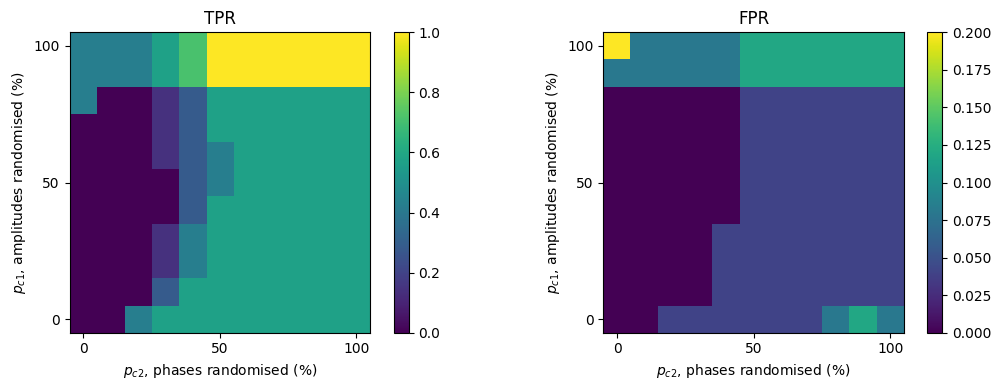

perfect cells: 0
where TPR = 1, FPR ranges over [0.12]


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = show_plane(axes[0], tpr_net, "TPR", cmap="viridis")
plt.colorbar(im, ax=axes[0])
im = show_plane(axes[1], fpr_net, "FPR", cmap="viridis", vmax=0.2)
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

print("perfect cells:", int(((tpr_net == 1) & (fpr_net == 0)).sum()))
best = tpr_net == 1
print("where TPR = 1, FPR ranges over", np.round(np.unique(fpr_net[best]), 2))

Three observations:

1. **Each link keeps the band of its own channel.** The phase links (1–2, 2–3, 5–6) are vertical
   bands and the amplitude links (3–4, 4–5, 6–7) horizontal bands, even at node 3, which has one
   of each. The link 7–8, which has both, is found through the phase alone, the channel that is
   easier to destroy.
2. **The whole network is found only where all bands overlap**, at high $p_{c1}$ and high
   $p_{c2}$. Anywhere else, only the links of one channel are found.
3. **No cell is perfect, because of the indirect pairs.** 1–3 has exactly the band of the phase
   links next to it, and 3–5 and 6–8 the band of the amplitude links: wherever all the links are
   found, the indirect pairs are found too. Choosing a different cell cannot fix this, because
   their maps are the same as those of real links.

## 7. Removing indirect pairs with partial correlation

An indirect pair is related only *through* a third node. A **partial correlation** measures the
relation between two nodes after removing what all the other nodes explain; it can be computed
from the inverse of the covariance matrix $P = \Sigma^{-1}$ as
$\rho_{ij \cdot \text{rest}} = -P_{ij} / \sqrt{P_{ii} P_{jj}}$.

We compute it in each channel separately:

- for the **amplitude**, on the logarithm of the Hilbert amplitudes;
- for the **phase**, on the short-time fluctuations of the phase: the unwrapped Hilbert phase
  minus its moving average over 40 points (10 time units). We cannot use the phases themselves,
  because the three nodes of a locked chain are all locked to each other.

In [13]:
def partial_correlation(X):
    P = np.linalg.inv(np.cov(X.T))
    d = np.sqrt(np.diag(P))
    return -P / np.outer(d, d)


z_net = hilbert(data_net - data_net.mean(axis=0), axis=0)
log_amplitude = np.log(np.abs(z_net))
phase = np.unwrap(np.angle(z_net), axis=0)
phase_fluctuation = phase - uniform_filter1d(phase, 40, axis=0, mode="nearest")

corr_amp, pcorr_amp = np.corrcoef(log_amplitude.T), partial_correlation(log_amplitude)
corr_ph, pcorr_ph = np.corrcoef(phase_fluctuation.T), partial_correlation(phase_fluctuation)

kind = {p: "phase link" for p in phase_links}
kind.update({p: "amplitude link" for p in amplitude_links})
kind.update({p: "both" for p in both_links})
kind.update({p: "indirect" for p in indirect_pairs})
rows = [{"pair": f"{i}-{j}", "type": kind[(i, j)],  # nodes i and j are rows i - 1 and j - 1
         "amplitude: corr.": corr_amp[i - 1, j - 1], "amplitude: partial": pcorr_amp[i - 1, j - 1],
         "phase fluct.: corr.": corr_ph[i - 1, j - 1], "phase fluct.: partial": pcorr_ph[i - 1, j - 1]}
        for (i, j) in kind]
pd.DataFrame(rows).sort_values("type").round(3)

,pair,type,amplitude: corr.,amplitude: partial,phase fluct.: corr.,phase fluct.: partial
3,3-4,amplitude link,0.815,0.620,0.085,0.061
4,4-5,amplitude link,0.811,0.611,0.078,0.053
5,6-7,amplitude link,0.816,0.666,0.076,0.050
6,7-8,both,0.805,0.643,0.347,0.338
7,1-3,indirect,0.024,0.026,0.075,0.033
8,3-5,indirect,0.674,0.040,0.049,0.020
9,6-8,indirect,0.632,-0.067,0.047,0.007
0,1-2,phase link,-0.001,-0.001,0.174,0.155
1,2-3,phase link,0.033,0.034,0.204,0.186
2,5-6,phase link,-0.011,-0.025,0.245,0.234


In the amplitude columns, the indirect pairs 3–5 and 6–8 are as correlated as real links (about
0.65 against 0.8), but their **partial** correlation drops to almost zero, while the links keep
about 0.6. In the phase columns, the partial correlation of the indirect pair 1–3 is also close to
zero, while the phase links stay clearly above it. So a two-step procedure works in this model:

1. use the APMSD grid to find the candidate links and, from the shape of each pair's region, the
   channel that carries it;
2. within each channel, remove the pairs whose partial correlation is close to zero.

This works so well here because the model is close to linear. For strongly nonlinear systems, such
as coupled neurons, partial correlations may not be enough, and conditional mutual information or
transfer entropy may be needed.

## Summary

- APMSD destroys the **amplitude** relations between nodes with $p_{c1}$ and the **phase**
  relations with $p_{c2}$. A link is detected only when the channel that carries it is destroyed:
  phase links appear in a vertical band, amplitude links in a horizontal band.
- In a network that mixes both kinds of link, the whole network is found only where the bands
  overlap, so the location of the good cells reflects how the nodes are coupled.
- Pairs that share a channel through a common neighbour behave exactly like links in every cell.
  Partial correlations, computed in the right channel, can remove them.

## Try it yourself

- Make the coupling weaker (`K=0.2` or `k=0.2` in `simulate_oscillators`): do the bands move or
  shrink?
- Change the memory of the amplitude, `tau`. Does the amplitude band start at a smaller $p_{c1}$
  when the amplitude changes faster?
- Couple M to D through both channels. Which band does the D–M link follow?
- Use a shorter time series (`n_points=5_000`) and see which links are lost first.

## References

1. <a id="ref-1" name="ref-1"></a>H. Yıldırım and C. G. Antonopoulos, Network inference using mutual information rate,
   statistical tests and amplitude-phase modulated surrogate data, *Chaos, Solitons & Fractals*
   188, 115554 (2024). <https://doi.org/10.1016/j.chaos.2024.115554>